In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import sys, json, math
import numpy as np, torch
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni
device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print('Device:', device)

W0811 13:55:39.701000 17143 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps


In [2]:
# BrainOmni-BASE, last-1 block, the two fixed splits, run to 400 epochs (full curve, no early stop).
# Best epoch still chosen on val loss, so the reported test accuracy is unaffected by the extra epochs.
CKPT = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection/base'
SAVE_DIR = '../data/preprocessed'; OUT_DIR = '../results/figures'
os.makedirs(OUT_DIR, exist_ok=True)
model_config = json.load(open(os.path.join(CKPT, 'model_cfg.json')))
base_checkpoint = torch.load(os.path.join(CKPT, 'BrainOmni.pt'), map_location='cpu', weights_only=True)
proj_out1 = np.load(os.path.join(SAVE_DIR, 'proj_out1_base.npy'))
proj_out2 = np.load(os.path.join(SAVE_DIR, 'proj_out2_base.npy'))
labels = np.load(os.path.join(SAVE_DIR, 'labels.npy')); N = len(labels)
BACKBONE_LR, HEAD_LR = 1e-5, 1e-4
N_FROZEN = 10       # last 1 block trainable
HDIM = 512          # base width
MAX_EPOCHS = 400

def make_split(labels, holdout, seed=123):
    idx = np.arange(len(labels))
    tr, tmp = train_test_split(idx, test_size=2*holdout, stratify=labels, random_state=seed)
    va, te  = train_test_split(tmp, test_size=0.5, stratify=labels[tmp], random_state=seed)
    return tr, va, te
SPLITS = {'80/10/10': make_split(labels, 0.10), '70/15/15': make_split(labels, 0.15)}
for name,(tr,va,te) in SPLITS.items(): print(f'{name}: train {len(tr)} | val {len(va)} | test {len(te)}')
print('base features:', proj_out1.shape, '| head dim', HDIM, '| epochs', MAX_EPOCHS)

80/10/10: train 118 | val 15 | test 15
70/15/15: train 103 | val 22 | test 23
base features: (148, 16, 160, 512) | head dim 512 | epochs 400


In [3]:
class CachedMEGDataset(Dataset):
    def __init__(self, idx, c1, c2, labels): self.i, self.c1, self.c2, self.y = idx, c1, c2, labels
    def __len__(self): return len(self.i)
    def __getitem__(self, k):
        j = self.i[k]; return self.c1[j], self.c2[j], torch.tensor(self.y[j], dtype=torch.long)

class FinetuneClassifier(nn.Module):
    def __init__(self, blocks, hidden_dim=HDIM):
        super().__init__(); self.blocks = blocks
        self.head = nn.Sequential(nn.Linear(hidden_dim*16, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 2))
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for b in self.blocks: x1 = b(x1); x2 = b(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2)/2).flatten(1))

def make_warmup_cosine(opt, total, warm=0.1, wmin=0.1, cmin=0.1):
    ws = max(1, int(total*warm))
    def f(s):
        if s < ws: return wmin + (1-wmin)*s/ws
        p=(s-ws)/max(1,total-ws); return cmin + (1-cmin)*0.5*(1+math.cos(math.pi*p))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def fresh_frozen_model():
    m = BrainOmni(**model_config); m.load_state_dict(base_checkpoint, strict=False)
    for p in m.parameters(): p.requires_grad = False
    return m.to(device).eval()

def cache_frozen(model, n_frozen):
    c1, c2 = [], []
    with torch.no_grad():
        for i in range(N):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for b in list(model.blocks)[:n_frozen]: x1 = b(x1); x2 = b(x2)
            c1.append(x1.squeeze(0).cpu()); c2.append(x2.squeeze(0).cpu())
    return c1, c2
print('Helpers 1 ready.')

Helpers 1 ready.


In [4]:
def train_split(tr, va, te, c1, c2, model, max_epochs=MAX_EPOCHS):
    tl = DataLoader(CachedMEGDataset(tr, c1, c2, labels), batch_size=8, shuffle=True)
    vl = DataLoader(CachedMEGDataset(va, c1, c2, labels), batch_size=8)
    mn = DataLoader(CachedMEGDataset(te, c1, c2, labels), batch_size=8)
    unfrozen = nn.ModuleList(list(model.blocks)[N_FROZEN:-1])
    for p in unfrozen.parameters(): p.requires_grad = True
    ft = FinetuneClassifier(unfrozen, HDIM).to(device)
    opt = torch.optim.AdamW([{'params': ft.blocks.parameters(), 'lr': BACKBONE_LR, 'weight_decay': 0.05},
                             {'params': ft.head.parameters(),   'lr': HEAD_LR,     'weight_decay': 0.05}],
                            betas=(0.9,0.99), eps=1e-6)
    sched = make_warmup_cosine(opt, max_epochs*len(tl)); crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    def ev(loader):
        ft.eval(); p,t,ls=[],[],0.0
        with torch.no_grad():
            for x1,x2,y in loader:
                o=ft(x1,x2); ls+=crit(o,y.to(device)).item(); p.extend(o.argmax(1).cpu().numpy()); t.extend(y.numpy())
        return accuracy_score(t,p), ls/len(loader)
    best_vl,best_ep,best_w=float('inf'),0,None
    ta,vacc,tl_,vlh,mona,monl=[],[],[],[],[],[]
    for ep in range(max_epochs):
        ft.train(); preds,trues,el=[],[],0.0
        for x1,x2,y in tl:
            opt.zero_grad(); o=ft(x1,x2); loss=crit(o,y.to(device)); loss.backward()
            torch.nn.utils.clip_grad_norm_(ft.parameters(),1.0); opt.step(); sched.step()
            el+=loss.item(); preds.extend(o.argmax(1).cpu().numpy()); trues.extend(y.numpy())
        tra,trl=accuracy_score(trues,preds), el/len(tl)
        va_,vll=ev(vl); ma_,mll=ev(mn)
        ta.append(tra); vacc.append(va_); tl_.append(trl); vlh.append(vll); mona.append(ma_); monl.append(mll)
        if vll < best_vl-1e-4:
            best_vl,best_ep=vll,ep+1; best_w={k:v.clone() for k,v in ft.state_dict().items()}
        if (ep+1)%50==0: print(f'    epoch {ep+1}/{max_epochs}  train_loss {trl:.3f}  test_acc {ma_:.3f}', flush=True)
    if best_w is not None: ft.load_state_dict(best_w)
    ft.eval(); yp=[]
    with torch.no_grad():
        for i in te: yp.append(ft(c1[i].unsqueeze(0), c2[i].unsqueeze(0)).argmax(1).item())
    return {'best_ep':best_ep,'test_acc':accuracy_score(labels[te],yp),
            'train_accs':ta,'val_accs':vacc,'mon_accs':mona,'train_losses':tl_,'val_losses':vlh,'mon_losses':monl}
print('Trainer ready.')

Trainer ready.


In [5]:
res = {}
for name, sp in SPLITS.items():
    print(f'=== base last-1 | {name} | {MAX_EPOCHS} epochs ===')
    model = fresh_frozen_model(); c1,c2 = cache_frozen(model, N_FROZEN)
    res[name] = train_split(sp[0], sp[1], sp[2], c1, c2, model)
    print(f'   best epoch {res[name]["best_ep"]} | test acc {res[name]["test_acc"]:.3f}')

=== base last-1 | 80/10/10 | 400 epochs ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


    epoch 50/400  train_loss 0.423  test_acc 0.733
    epoch 100/400  train_loss 0.348  test_acc 0.800
    epoch 150/400  train_loss 0.276  test_acc 0.733
    epoch 200/400  train_loss 0.233  test_acc 0.600
    epoch 250/400  train_loss 0.220  test_acc 0.667
    epoch 300/400  train_loss 0.214  test_acc 0.667
    epoch 350/400  train_loss 0.214  test_acc 0.600
    epoch 400/400  train_loss 0.213  test_acc 0.600
   best epoch 207 | test acc 0.600
=== base last-1 | 70/15/15 | 400 epochs ===


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


    epoch 50/400  train_loss 0.417  test_acc 0.913
    epoch 100/400  train_loss 0.330  test_acc 0.826
    epoch 150/400  train_loss 0.264  test_acc 0.870
    epoch 200/400  train_loss 0.254  test_acc 0.870
    epoch 250/400  train_loss 0.228  test_acc 0.870
    epoch 300/400  train_loss 0.217  test_acc 0.826
    epoch 350/400  train_loss 0.217  test_acc 0.870
    epoch 400/400  train_loss 0.215  test_acc 0.870
   best epoch 81 | test acc 0.870


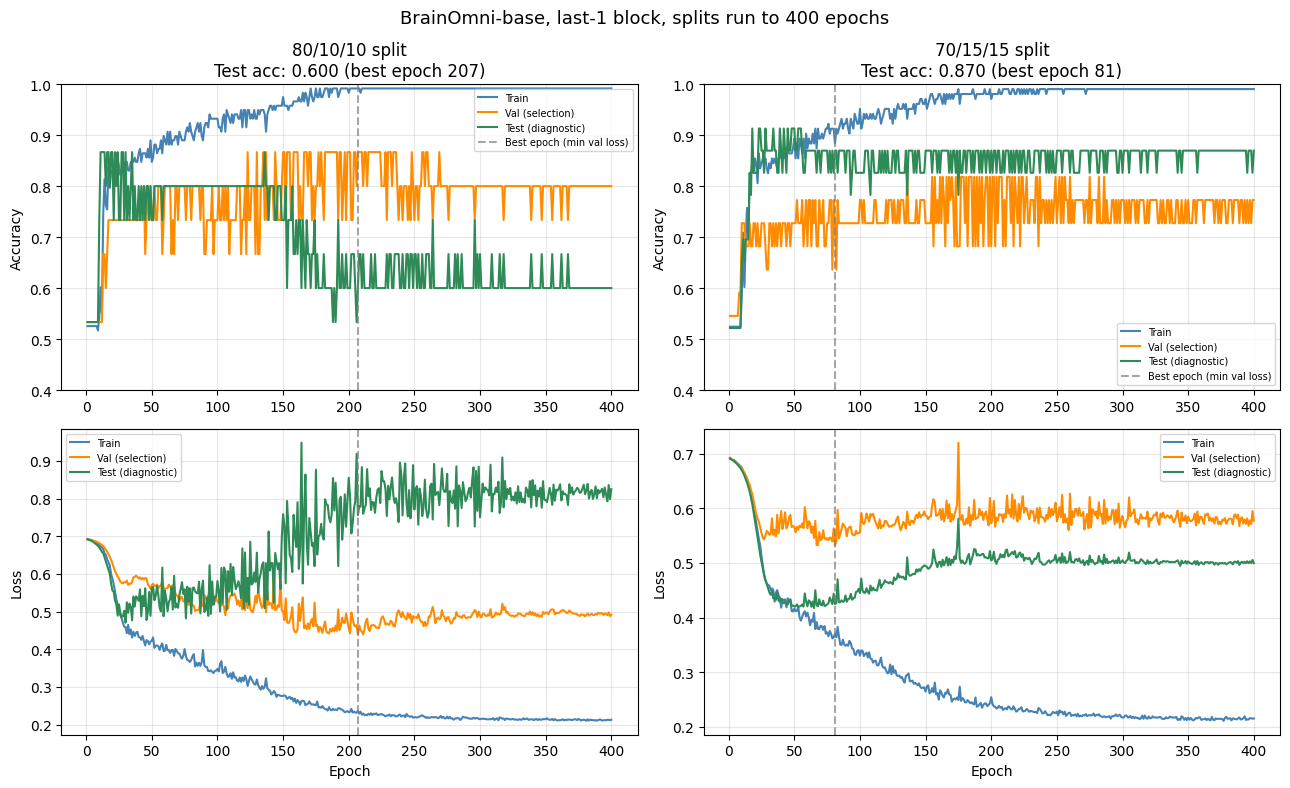

Saved nn_curves_last1_base_400.png


In [6]:
# Split learning curves (Train / Val / Test), last-1 block, base, 400 epochs
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for col, name in enumerate(['80/10/10', '70/15/15']):
    r = res[name]; ep = range(1, len(r['train_accs'])+1)
    axes[0,col].plot(ep, r['train_accs'], color='steelblue', label='Train')
    axes[0,col].plot(ep, r['val_accs'],   color='darkorange', label='Val (selection)')
    axes[0,col].plot(ep, r['mon_accs'],   color='seagreen',  label='Test (diagnostic)')
    axes[0,col].axvline(r['best_ep'], color='gray', ls='--', alpha=0.7, label='Best epoch (min val loss)')
    axes[0,col].set_title(f'{name} split\nTest acc: {r["test_acc"]:.3f} (best epoch {r["best_ep"]})')
    axes[0,col].set_ylabel('Accuracy'); axes[0,col].set_ylim(0.4,1.0); axes[0,col].legend(fontsize=7); axes[0,col].grid(alpha=0.3)
    axes[1,col].plot(ep, r['train_losses'], color='steelblue', label='Train')
    axes[1,col].plot(ep, r['val_losses'],   color='darkorange', label='Val (selection)')
    axes[1,col].plot(ep, r['mon_losses'],   color='seagreen',  label='Test (diagnostic)')
    axes[1,col].axvline(r['best_ep'], color='gray', ls='--', alpha=0.7)
    axes[1,col].set_xlabel('Epoch'); axes[1,col].set_ylabel('Loss'); axes[1,col].legend(fontsize=7); axes[1,col].grid(alpha=0.3)
fig.suptitle('BrainOmni-base, last-1 block, splits run to 400 epochs', fontsize=13)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'nn_curves_last1_base_400.png'), dpi=150); plt.show()
print('Saved nn_curves_last1_base_400.png')